# remake the edges via reactome intercellular linking + lr pairs

STEP 1 — Load UniProt → gene symbol map
  Loaded 165,580 UniProt → symbol entries

STEP 2 — Download Reactome data

STEP 3 — UniProt subcellular locations
  Using cached: uniprot_subcellular_human.tsv
  Extracellular/membrane proteins: 5,766
    'Secreted': 2,147
    'Extracellular space': 360
    'Extracellular matrix': 280
    'Cell membrane': 4,045
    'Plasma membrane': 493

STEP 4 — Filter to intercellular interactions
  Total interactions: 123,895
  Removed 7,771 self-interactions
  Interactor 1 extracellular: 34,253
  Interactor 2 extracellular: 31,372
  Both extracellular:         16,332
  Survival rate:              14.1%
  Saved → reactome_intercellular_interactions.csv

  Spot checks:
    TGFB1 ↔ TGFBR1: ✅
    IL6 ↔ IL6R: ✅
    EGF ↔ EGFR: ❌ MISSING

STEP 5 — Annotate interactions with Reactome pathways
  Before dedup: 16,332 rows
  After dedup:  4,843 unique protein pairs
  With common pathway: 4,671
  Saved → reactome_interactions_with_pathways_v2.csv (4,840 rows)

STEP 6 

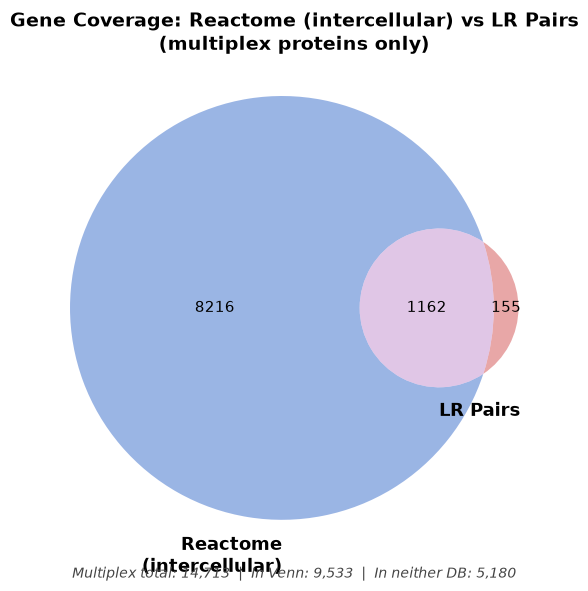

  Saved venn_multiplex_reactome.png

DONE
  reactome_intercellular_interactions.csv  — all intercellular pairs
  reactome_interactions_with_pathways_v2.csv — pairs with pathway annotations
  lr_pairs_with_pathways.csv  — LR pairs with shared pathways
  venn_multiplex_reactome.png          — Venn diagram


In [3]:
#!/usr/bin/env python3
"""
pipeline.py
===========
Single pipeline for Reactome intercellular interaction analysis.
Replaces: main script + rebuild_reactome_csv.py + merge_reactome_kegg.py

Outputs:
  - reactome_intercellular_interactions.csv   (all intercellular pairs)
  - reactome_interactions_with_pathways_v2.csv (pairs with pathway annotations)
  - lr_pairs_with_pathways.csv                (LR pairs with shared pathways)
  - venn_multiplex_reactome.png
"""
import os
import re
import pickle
import requests
import pandas as pd
import numpy as np
import networkx as nx
from pathlib import Path
from collections import Counter
import matplotlib.pyplot as plt
from matplotlib_venn import venn2

# ── File paths ────────────────────────────────────────────────────────────────
UNIPROT_SYM_CSV       = Path("../../og_gene_set/ppi_chloe/d_uniprot_to_symbol_20251120.csv")
UNIPROT_SUBCELL_TSV   = Path("uniprot_subcellular_human.tsv")   # cached after first run
LR_PAIRS_CSV          = Path("human_lr_pairs.csv")
LAYERS_DIR_1          = Path("../multiplex_ts/layers")
LAYERS_DIR_2          = Path("../multiplex_2025hdrg/layers")

# Outputs
OUT_INTERACTIONS      = Path("reactome_intercellular_interactions.csv")
OUT_REACTOME_CSV      = Path("reactome_interactions_with_pathways_v2.csv")
OUT_LR_PATHWAYS       = Path("lr_pairs_with_pathways.csv")
OUT_VENN              = Path("venn_multiplex_reactome.png")

# ── Toggles ───────────────────────────────────────────────────────────────────
INCLUDE_LR_PAIRS      = True    # set False to skip LR pair mapping

# ============================================================================
# DOWNLOAD FUNCTIONS
# ============================================================================
def download_csv(url, output_file, sep='\t', header=None, col_names=None):
    response = requests.get(url, timeout=60)
    response.raise_for_status()
    with open(output_file, 'w') as f:
        f.write(response.text)
    df = pd.read_csv(output_file, sep=sep, header=header)
    if col_names:
        df.columns = col_names
    return df

def download_interactions():
    return download_csv(
        url='https://download.reactome.org/96/interactors/reactome.homo_sapiens.interactions.tab-delimited.txt',
        output_file='reactome_interactions_human.txt',
        sep='\t', header=0
    )

def download_uniprot_to_pathways():
    return download_csv(
        url='https://download.reactome.org/96/UniProt2Reactome_All_Levels.txt',
        output_file='uniprot_to_pathways.txt',
        col_names=['uniprot_id', 'reactome_id', 'url',
                   'pathway_name', 'evidence_code', 'species']
    )

def download_uniprot_subcellular():
    """Downloads human SwissProt subcellular location annotations."""
    url = (
        'https://rest.uniprot.org/uniprotkb/stream?'
        'query=organism_id:9606+AND+reviewed:true'
        '&fields=accession,cc_subcellular_location'
        '&format=tsv'
    )
    print("  Downloading UniProt subcellular locations...")
    response = requests.get(url, timeout=120)
    response.raise_for_status()
    with open(UNIPROT_SUBCELL_TSV, 'w') as f:
        f.write(response.text)
    df = pd.read_csv(UNIPROT_SUBCELL_TSV, sep='\t')
    df.columns = ['uniprot_id', 'subcellular_location']
    print(f"  Downloaded {len(df):,} entries")
    return df

# ============================================================================
# LAYER FUNCTIONS
# ============================================================================
def load_layers(layers_dir):
    layers = {}
    for fname in sorted(f for f in os.listdir(layers_dir) if f.endswith('_layer.pkl')):
        cell_type = fname.replace('_layer.pkl', '')
        with open(os.path.join(layers_dir, fname), 'rb') as f:
            layers[cell_type] = pickle.load(f)
    print(f"  Loaded {len(layers)} layers from {layers_dir}")
    return layers

def get_multiplex_proteins(layers):
    proteins = set()
    for layer in layers.values():
        proteins.update(layer.nodes())
    return proteins

def convert_nodes_to_uniprot(layers, symbol_to_uniprot):
    converted = {}
    for cell_type, layer in layers.items():
        mapping = {
            node: symbol_to_uniprot.get(str(node).upper(), node)
            for node in layer.nodes()
        }
        converted[cell_type] = nx.relabel_nodes(layer, mapping)
    return converted

# ============================================================================
# INTERCELLULAR FILTER
# ============================================================================
def get_extracellular_proteins(subcellular_df):
    """
    Returns set of UniProt IDs annotated as extracellular/membrane.
    These are proteins capable of mediating intercellular interactions.
    """
    intercellular_terms = [
        'Secreted', 'Extracellular space', 'Extracellular matrix',
        'Cell membrane', 'Plasma membrane'
    ]
    pattern = '|'.join(intercellular_terms)
    mask    = subcellular_df['subcellular_location'].str.contains(
        pattern, case=False, na=False
    )
    extracellular_set = set(
        subcellular_df[mask]['uniprot_id'].str.strip().str.upper()
    )
    print(f"  Extracellular/membrane proteins: {len(extracellular_set):,}")
    for term in intercellular_terms:
        n = subcellular_df['subcellular_location'].str.contains(
            term, case=False, na=False
        ).sum()
        print(f"    '{term}': {n:,}")
    return extracellular_set

def filter_intercellular_interactions(interactions_df, extracellular_proteins):
    """
    Keeps interactions where BOTH proteins are extracellular/membrane.
    Also strips UniProt prefixes and drops self-interactions.
    """
    print(f"  Total interactions: {len(interactions_df):,}")

    uniprot_cols = [c for c in interactions_df.columns if "uniprot" in c.lower()]
    col1, col2   = uniprot_cols[0], uniprot_cols[1]

    df = interactions_df.copy()
    df["uniprot1"] = (
        df[col1].astype(str)
        .str.replace("uniprotkb:", "", regex=False)
        .str.strip().str.upper()
    )
    df["uniprot2"] = (
        df[col2].astype(str)
        .str.replace("uniprotkb:", "", regex=False)
        .str.strip().str.upper()
    )

    # Drop self-interactions
    before = len(df)
    df     = df[df["uniprot1"] != df["uniprot2"]].copy()
    print(f"  Removed {before - len(df):,} self-interactions")

    # Intercellular filter
    mask1    = df["uniprot1"].isin(extracellular_proteins)
    mask2    = df["uniprot2"].isin(extracellular_proteins)
    filtered = df[mask1 & mask2].copy()

    print(f"  Interactor 1 extracellular: {mask1.sum():,}")
    print(f"  Interactor 2 extracellular: {mask2.sum():,}")
    print(f"  Both extracellular:         {len(filtered):,}")
    print(f"  Survival rate:              "
          f"{100*len(filtered)/max(len(df),1):.1f}%")
    return filtered

# ============================================================================
# PATHWAY LOOKUP
# ============================================================================
def build_reactome_pathway_lookup(uniprot_pathways_df, uniprot_to_symbol):
    """
    Returns DataFrame: gene_symbol | pathway_names (pipe-sep) | sources
    Human Reactome only, whitespace stripped.
    """
    reactome = (
        uniprot_pathways_df[uniprot_pathways_df['species'] == 'Homo sapiens']
        [['uniprot_id', 'pathway_name']]
        .copy()
    )
    reactome['pathway_name'] = reactome['pathway_name'].str.strip()
    reactome['gene_symbol']  = (
        reactome['uniprot_id']
        .map(uniprot_to_symbol)
        .str.strip()
        .str.upper()
    )
    reactome['source'] = 'Reactome'
    reactome = (
        reactome
        .dropna(subset=['gene_symbol'])
        [['gene_symbol', 'pathway_name', 'source']]
    )

    print(f"  Reactome rows (human): {len(reactome):,}")
    print(f"  Unique gene symbols:   {reactome['gene_symbol'].nunique():,}")
    print(f"  Unique pathways:       {reactome['pathway_name'].nunique():,}")

    lookup = (
        reactome
        .groupby('gene_symbol', sort=False)
        .agg(
            pathway_names=pd.NamedAgg(
                column='pathway_name',
                aggfunc=lambda x: '|'.join(sorted({p.strip() for p in x}))
            ),
            sources=pd.NamedAgg(
                column='source',
                aggfunc=lambda x: '|'.join(sorted(set(x)))
            )
        )
        .reset_index()
    )
    print(f"  Lookup: {len(lookup):,} unique gene symbols")
    return lookup

# ============================================================================
# PATHWAY ANNOTATION FOR INTERACTION PAIRS
# ============================================================================
def annotate_interactions_with_pathways(interactions_df, uniprot_pathways_df):
    """
    Merges Reactome pathway annotations onto interaction pairs,
    computes common pathways, deduplicates to one row per protein pair.
    """
    # Collapse pathways per UniProt ID
    up_human = uniprot_pathways_df[
        uniprot_pathways_df['species'] == 'Homo sapiens'
    ].copy()
    up_human['uniprot_id']   = up_human['uniprot_id'].str.strip().str.upper()
    up_human['pathway_name'] = up_human['pathway_name'].str.strip()

    reactome_collapsed = (
        up_human
        .groupby('uniprot_id')['pathway_name']
        .apply(lambda x: '|'.join(sorted({p.strip() for p in x})))
        .reset_index()
        .rename(columns={'pathway_name': 'reactome_pathways'})
    )

    def _split(val) -> set:
        if pd.isna(val) or str(val).strip() in ('', 'nan', 'NAN'):
            return set()
        return {p.strip() for p in str(val).split('|') if p.strip()}

    # Merge for protein 1
    merged = interactions_df.merge(
        reactome_collapsed.rename(columns={
            'uniprot_id': 'uid1', 'reactome_pathways': 'reactome_p1'
        }),
        left_on='uniprot1', right_on='uid1', how='left'
    ).drop(columns='uid1', errors='ignore')

    # Merge for protein 2
    merged = merged.merge(
        reactome_collapsed.rename(columns={
            'uniprot_id': 'uid2', 'reactome_pathways': 'reactome_p2'
        }),
        left_on='uniprot2', right_on='uid2', how='left'
    ).drop(columns='uid2', errors='ignore')

    # Compute common pathways
    merged['common_pathway'] = merged.apply(
        lambda row: (
            '|'.join(sorted(_split(row['reactome_p1']) & _split(row['reactome_p2'])))
            or None
        ),
        axis=1
    )
    merged['pathway_source'] = merged['common_pathway'].apply(
        lambda x: 'Reactome' if pd.notna(x) else None
    )

    # Deduplicate to one row per protein pair
    merged['pair_key'] = merged.apply(
        lambda r: tuple(sorted([r['uniprot1'], r['uniprot2']])), axis=1
    )
    before = len(merged)
    merged_unique = (
        merged
        .groupby('pair_key', sort=False)
        .agg(
            uniprot1=('uniprot1', 'first'),
            uniprot2=('uniprot2', 'first'),
            symbol1=('symbol1',  'first'),
            symbol2=('symbol2',  'first'),
            common_pathway=('common_pathway',
                lambda x: '|'.join(sorted({
                    p for val in x.dropna()
                    for p in str(val).split('|') if p.strip()
                })) or None),
            pathway_source=('pathway_source', 'first'),
            reactome_p1=('reactome_p1', 'first'),
            reactome_p2=('reactome_p2', 'first'),
            n_reaction_contexts=('pair_key', 'count'),
        )
        .reset_index(drop=True)
    )
    merged_unique['common_pathway'] = merged_unique['common_pathway'].replace('', None)

    print(f"  Before dedup: {before:,} rows")
    print(f"  After dedup:  {len(merged_unique):,} unique protein pairs")
    print(f"  With common pathway: {merged_unique['common_pathway'].notna().sum():,}")
    return merged_unique

# ============================================================================
# LR PAIR PATHWAY MAPPING
# ============================================================================
def map_lr_to_pathways(lr_df, lookup_df):
    """Adds shared Reactome pathway columns to LR pairs."""
    idx = lookup_df.set_index('gene_symbol')

    def get_field(gene, field):
        gene_up = str(gene).strip().upper() if pd.notna(gene) else None
        if gene_up and gene_up in idx.index:
            return idx.at[gene_up, field]
        return None

    result = lr_df.copy()
    result['ligand_pathways']   = result['ligand_gname'].map(
        lambda g: get_field(g, 'pathway_names')
    )
    result['ligand_sources']    = result['ligand_gname'].map(
        lambda g: get_field(g, 'sources')
    )
    result['receptor_pathways'] = result['receptor_gname'].map(
        lambda g: get_field(g, 'pathway_names')
    )
    result['receptor_sources']  = result['receptor_gname'].map(
        lambda g: get_field(g, 'sources')
    )

    def common_pathways(row):
        p1 = {p.strip() for p in row['ligand_pathways'].split('|')} \
             if pd.notna(row['ligand_pathways']) else set()
        p2 = {p.strip() for p in row['receptor_pathways'].split('|')} \
             if pd.notna(row['receptor_pathways']) else set()
        common = p1 & p2
        return '|'.join(sorted(common)) if common else None

    result['common_pathways']   = result.apply(common_pathways, axis=1)
    result['n_common_pathways'] = result['common_pathways'].apply(
        lambda x: len(x.split('|')) if pd.notna(x) else 0
    )
    return result

# ============================================================================
# VENN DIAGRAM
# ============================================================================
def plot_venn(reactome_syms, lr_syms, multiplex_syms,
              save_path=OUT_VENN):
    reactome_syms = reactome_syms & multiplex_syms
    lr_syms       = lr_syms       & multiplex_syms

    r_only  = reactome_syms - lr_syms
    lr_only = lr_syms - reactome_syms
    both    = reactome_syms & lr_syms
    in_none = multiplex_syms - reactome_syms - lr_syms

    # Verify counts add up
    assert len(r_only) + len(lr_only) + len(both) + len(in_none) == len(multiplex_syms)

    fig, ax = plt.subplots(figsize=(8, 6))
    v = venn2(
        subsets=(len(r_only), len(lr_only), len(both)),
        set_labels=('Reactome\n(intercellular)', 'LR Pairs'),
        ax=ax, alpha=0.55,
        set_colors=('#4878CF', '#D65F5F'),
    )
    for lbl in v.set_labels:
        if lbl:
            lbl.set_fontsize(13)
            lbl.set_fontweight('bold')
    for lbl in v.subset_labels:
        if lbl:
            lbl.set_fontsize(11)

    ax.set_title(
        'Gene Coverage: Reactome (intercellular) vs LR Pairs\n'
        '(multiplex proteins only)',
        fontsize=14, fontweight='bold'
    )
    ax.annotate(
        f"Multiplex total: {len(multiplex_syms):,}  "
        f"|  In Venn: {len(reactome_syms | lr_syms):,}  "
        f"|  In neither DB: {len(in_none):,}",
        xy=(0.5, -0.04), xycoords='axes fraction',
        ha='center', fontsize=10, color='#444', style='italic'
    )
    plt.tight_layout()
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"  Saved {save_path}")

# ============================================================================
# MAIN
# ============================================================================
if __name__ == "__main__":

    # ── Step 1 — UniProt → symbol mapping ────────────────────────────────────
    print("=" * 70)
    print("STEP 1 — Load UniProt → gene symbol map")
    print("=" * 70)
    mapping_df        = pd.read_csv(UNIPROT_SYM_CSV)
    mapping_df.columns = mapping_df.columns.str.strip().str.lower()
    uid_col = next(c for c in mapping_df.columns
                   if c in ("uniprotid", "uniprot_id", "uniprot"))
    sym_col = next(c for c in mapping_df.columns
                   if c in ("symbol", "gene_symbol", "genesymbol"))
    uniprot_to_symbol = dict(zip(
        mapping_df[uid_col].str.strip().str.upper(),
        mapping_df[sym_col].str.strip().str.upper()
    ))
    symbol_to_uniprot = {v: k for k, v in uniprot_to_symbol.items()}
    print(f"  Loaded {len(uniprot_to_symbol):,} UniProt → symbol entries")

    # ── Step 2 — Download Reactome data ──────────────────────────────────────
    print("\n" + "=" * 70)
    print("STEP 2 — Download Reactome data")
    print("=" * 70)
    interactions_df     = download_interactions()
    uniprot_pathways_df = download_uniprot_to_pathways()

    # ── Step 3 — Subcellular locations ───────────────────────────────────────
    print("\n" + "=" * 70)
    print("STEP 3 — UniProt subcellular locations")
    print("=" * 70)
    if UNIPROT_SUBCELL_TSV.exists():
        print(f"  Using cached: {UNIPROT_SUBCELL_TSV}")
        subcell_df = pd.read_csv(UNIPROT_SUBCELL_TSV, sep='\t')
        subcell_df.columns = ['uniprot_id', 'subcellular_location']
    else:
        subcell_df = download_uniprot_subcellular()

    extracellular_proteins = get_extracellular_proteins(subcell_df)

    # ── Step 4 — Filter to intercellular interactions ─────────────────────────
    print("\n" + "=" * 70)
    print("STEP 4 — Filter to intercellular interactions")
    print("=" * 70)
    intercellular_df = filter_intercellular_interactions(
        interactions_df, extracellular_proteins
    )

    # Add gene symbols
    intercellular_df['symbol1'] = intercellular_df['uniprot1'].map(uniprot_to_symbol)
    intercellular_df['symbol2'] = intercellular_df['uniprot2'].map(uniprot_to_symbol)
    intercellular_df.to_csv(OUT_INTERACTIONS, index=False)
    print(f"  Saved → {OUT_INTERACTIONS}")

    # Spot check known pairs
    known_pairs = [('TGFB1', 'TGFBR1'), ('IL6', 'IL6R'), ('EGF', 'EGFR')]
    print("\n  Spot checks:")
    for lig, rec in known_pairs:
        found = (
            (
                (intercellular_df['symbol1'] == lig) &
                (intercellular_df['symbol2'] == rec)
            ) | (
                (intercellular_df['symbol1'] == rec) &
                (intercellular_df['symbol2'] == lig)
            )
        ).any()
        print(f"    {lig} ↔ {rec}: {'✅' if found else '❌ MISSING'}")

    # ── Step 5 — Annotate with pathways ──────────────────────────────────────
    print("\n" + "=" * 70)
    print("STEP 5 — Annotate interactions with Reactome pathways")
    print("=" * 70)
    annotated_df = annotate_interactions_with_pathways(
        intercellular_df, uniprot_pathways_df
    )
    # Drop symbol self-pairs
    annotated_df = annotated_df[
        annotated_df['symbol1'] != annotated_df['symbol2']
    ].copy()
    annotated_df.to_csv(OUT_REACTOME_CSV, index=False)
    print(f"  Saved → {OUT_REACTOME_CSV} ({len(annotated_df):,} rows)")

    # ── Step 6 — Load multiplex layers ───────────────────────────────────────
    print("\n" + "=" * 70)
    print("STEP 6 — Load multiplex layers")
    print("=" * 70)
    layers_1 = load_layers(LAYERS_DIR_1)
    layers_2 = load_layers(LAYERS_DIR_2)
    layers   = {**layers_1, **layers_2}

    converted_layers   = convert_nodes_to_uniprot(layers, symbol_to_uniprot)
    multiplex_proteins = get_multiplex_proteins(converted_layers)
    multiplex_symbols  = {
        uniprot_to_symbol[p].upper()
        for p in multiplex_proteins
        if p in uniprot_to_symbol
    }
    print(f"  Multiplex: {len(multiplex_proteins):,} UniProt IDs "
          f"→ {len(multiplex_symbols):,} gene symbols")

    # ── Step 7 — Build pathway lookup and map LR pairs ───────────────────────
    print("\n" + "=" * 70)
    print("STEP 7 — Build pathway lookup")
    print("=" * 70)
    lookup_df = build_reactome_pathway_lookup(uniprot_pathways_df, uniprot_to_symbol)

    if INCLUDE_LR_PAIRS and LR_PAIRS_CSV.exists():
        print("\n" + "=" * 70)
        print("STEP 8 — Map LR pairs to pathways")
        print("=" * 70)
        lr_pairs         = pd.read_csv(LR_PAIRS_CSV)
        lr_with_pathways = map_lr_to_pathways(lr_pairs, lookup_df)
        lr_with_pathways.to_csv(OUT_LR_PATHWAYS, index=False)

        total      = len(lr_with_pathways)
        has_common = lr_with_pathways['common_pathways'].notna().sum()
        print(f"  LR pairs with ≥1 shared pathway: {has_common:,} / {total:,} "
              f"({100*has_common/total:.1f}%)")

        print("\n  Top 20 shared pathways:")
        counter = Counter(
            p for val in lr_with_pathways['common_pathways'].dropna()
            for p in val.split('|')
        )
        for pathway, n in counter.most_common(20):
            print(f"    {n:>5}  {pathway}")

        lr_syms = (
            set(lr_pairs['ligand_gname'].str.upper().dropna()) |
            set(lr_pairs['receptor_gname'].str.upper().dropna())
        )
    else:
        print("\n  STEP 8 — LR pairs skipped (INCLUDE_LR_PAIRS=False)")
        lr_syms = set()

    # ── Step 9 — Venn diagram ─────────────────────────────────────────────────
    print("\n" + "=" * 70)
    print("STEP 9 — Venn diagram")
    print("=" * 70)
    reactome_syms = set(lookup_df['gene_symbol']) & multiplex_symbols
    plot_venn(reactome_syms, lr_syms, multiplex_symbols, save_path=OUT_VENN)

    print("\n" + "=" * 70)
    print("DONE")
    print("=" * 70)
    print(f"  {OUT_INTERACTIONS}  — all intercellular pairs")
    print(f"  {OUT_REACTOME_CSV} — pairs with pathway annotations")
    if INCLUDE_LR_PAIRS:
        print(f"  {OUT_LR_PATHWAYS}  — LR pairs with shared pathways")
    print(f"  {OUT_VENN}          — Venn diagram")

In [2]:
pip install requests

  Using cached requests-2.34.2-py3-none-any.whl.metadata (4.8 kB)
  Using cached charset_normalizer-3.4.7-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.manylinux_2_28_x86_64.whl.metadata (40 kB)
  Using cached urllib3-2.7.0-py3-none-any.whl.metadata (6.9 kB)
Using cached requests-2.34.2-py3-none-any.whl (73 kB)
Using cached charset_normalizer-3.4.7-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.manylinux_2_28_x86_64.whl (216 kB)
Using cached urllib3-2.7.0-py3-none-any.whl (131 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [requests]4/5 [requests]
Note: you may need to restart the kernel to use updated packages.
